# 2026-10-08 — Claude review fixes

## Stage 1 grid fix (`01_climada_intensity_main.py`)

**Bug.** `generate_intensity_per_storm` and `compute_yearly_exposure_per_storm` cropped each storm with
`dropna(dim, how="all")`, which also removes *interior* all-NaN rows/columns, e.g. the gap between two disjoint
pieces of a footprint. `to_raster` then took the **mean** coordinate step, so a raster with a gap got a stretched
resolution, and `clip_raster_to_land` rebuilt evenly spaced coords at that wrong step. The values were stored at the
wrong locations, and the land clip was evaluated at those wrong locations too.

**Fix.** `crop_to_footprint` crops to the bounding box of finite values and keeps the interior empty rows/cols, so the grid
stays at 0.1°. `to_raster` now raises if the coords are not uniformly spaced, instead of silently averaging.

**Scope in production `stage1_v2`.** ~68% of stored storms (sample of 19,736 intensity + exposure arrays, all basins)
sit on a grid coarser than 0.1°. Stages 2–4 consume these rasters, so all of them inherit the displacement.

**Figure.** Two storms from the test draw (NI, draw 53). *Ground truth* is CLIMADA's intensity on the full basin grid.
*Before* is what production stored. *After* is the fixed Stage 1 path. "Misplaced" counts stored pixels whose value differs
from CLIMADA's value at the same coordinate. The × marks the true peak on land; the ○ marks where production stored it.

_Runs in `climada_env` (CLIMADA recomputes 2 storms, ~1 min). Reads production data read-only; writes nothing._

In [1]:
import os, warnings
from pathlib import Path

os.environ.setdefault("PROJ_LIB", "/mnt/share/code/mfiking/miniconda3/envs/climada_env/share/proj")
os.environ.setdefault("PROJ_DATA", "/mnt/share/code/mfiking/miniconda3/envs/climada_env/share/proj")
warnings.filterwarnings("ignore")

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

REPO = Path("/ihme/homes/mfiking/github_repos/climada_python")
PROD_STAGE1 = Path("/mnt/team/rapidresponse/pub/tropical-storms/climada/output/stage1_v2")

# Test case: one NI draw, reviewed 2026-10-08
SOURCE, VARIANT, EXPERIMENT, BATCH, BASIN, DRAW = "MRI-ESM2-0", "r4i1p1f1", "ssp585", "2025-2029", "NI", 53
STORMS = [6, 18]

# Load the (fixed) Stage 1 function definitions without running its CLI / main().
_src = (REPO / "script/climada/01_climada_intensity_main.py").read_text()
_src = (
    _src.split("parser = argparse.ArgumentParser")[0]
    + _src.split("num_cores = args.num_cores")[1].split("\nmain(")[0]
)
s1 = {}
exec(compile(_src, "01_climada_intensity_main.py", "exec"), s1)

In [2]:
def mismatch_vs_truth(stored: xr.DataArray, truth: xr.DataArray) -> tuple[int, int]:
    """Count stored pixels whose value differs from CLIMADA's value at the same coordinate."""
    fin = np.isfinite(stored.values)
    lon2d, lat2d = np.meshgrid(stored.lon.values, stored.lat.values)
    j = np.rint((lon2d[fin] - truth.lon.values[0]) / 0.1).astype(int)
    i = np.rint((truth.lat.values[0] - lat2d[fin]) / 0.1).astype(int)
    return int((np.abs(truth.values[i, j] - stored.values[fin]) > 1e-3).sum()), int(fin.sum())


nc_file = s1["read_custom_tracks_nc"](SOURCE, VARIANT, EXPERIMENT, BATCH, BASIN, DRAW)
centroids = s1["generate_basin_centroids"](BASIN, res=0.1)
land_gdf_all = s1["load_global_land_gdf"](BASIN)
zarr_name = f"intensity_{BASIN}_{SOURCE}_{EXPERIMENT}_{VARIANT}_{BATCH[:4]}01_{BATCH[-4:]}12_e{DRAW - 1}.zarr"
prod_store = PROD_STAGE1 / SOURCE / VARIANT / EXPERIMENT / BATCH / BASIN / "intensity" / zarr_name

results = {}
with xr.open_dataset(nc_file) as ds_all:
    for idx in STORMS:
        ds_track = s1["read_single_storm_from_dataset"](ds_all, idx)
        tracks = s1["prepare_track_for_climada"](ds_track)
        haz = s1["generate_hazard_per_track"](tracks, centroids)

        # Ground truth: CLIMADA intensity on the full basin grid (no cropping, no land clip)
        lon = np.unique(centroids.coord[:, 1])
        lat = np.sort(np.unique(centroids.coord[:, 0]))[::-1]
        truth = xr.DataArray(
            haz.intensity.toarray()[0].reshape(lat.size, lon.size),
            coords={"lat": lat, "lon": lon}, dims=["lat", "lon"],
        )

        # After: the fixed Stage 1 path (crop_to_footprint -> land subset -> clip_raster_to_land)
        after = s1["generate_intensity_per_storm"](haz, centroids, tracks)
        land = s1["subset_land_for_storm"](land_gdf_all, after, BASIN, buffer=0.25)
        after = s1["clip_raster_to_land"](after, land.geometry.union_all())

        # Before: what production stage1_v2 stored for the same storm
        before = xr.open_zarr(prod_store, group=f"storm_{idx:04d}", consolidated=False)["intensity"].load()

        results[idx] = dict(
            truth=truth, before=before, after=after, land=land,
            track=(tracks.data[0].lon.values, tracks.data[0].lat.values),
            before_mis=mismatch_vs_truth(before, truth), after_mis=mismatch_vs_truth(after, truth),
            before_step=float(np.abs(np.diff(before.lon.values)).mean()),
            after_step=float(np.abs(np.diff(after.lon.values)).mean()),
        )
        print(
            f"storm {idx}: before step={results[idx]['before_step']:.3f}° "
            f"misplaced {results[idx]['before_mis'][0]}/{results[idx]['before_mis'][1]} px | "
            f"after step={results[idx]['after_step']:.3f}° "
            f"misplaced {results[idx]['after_mis'][0]}/{results[idx]['after_mis'][1]} px"
        )

storm 6: before step=0.152° misplaced 1092/1092 px | after step=0.100° misplaced 0/621 px
storm 18: before step=0.194° misplaced 829/829 px | after step=0.100° misplaced 0/829 px

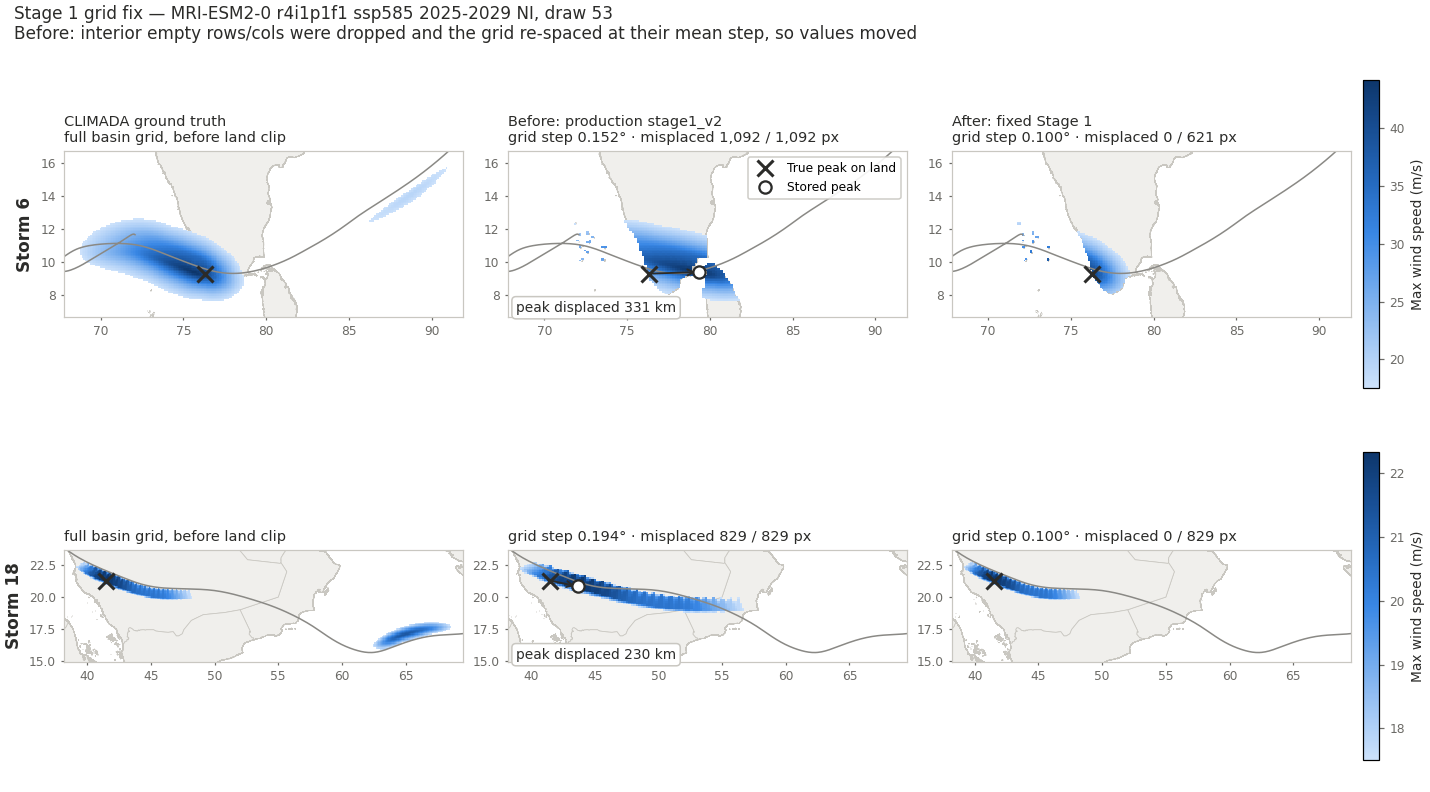

In [3]:
# Sequential single-hue ramp (light -> dark blue) for wind speed magnitude
BLUE_RAMP = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
CMAP = LinearSegmentedColormap.from_list("wind_blue", BLUE_RAMP)
INK, INK_MUTED, LAND_FILL, LAND_EDGE, TRACK = "#2b2b29", "#6b6a66", "#f0efec", "#c9c7c1", "#8a8985"


def peak(da: xr.DataArray) -> tuple[float, float]:
    """(lon, lat) of the maximum value in a DataArray."""
    i, j = np.unravel_index(np.nanargmax(da.values), da.shape)
    return float(da.lon[j]), float(da.lat[i])


def km_between(a, b) -> float:
    lon1, lat1, lon2, lat2 = map(np.radians, (*a, *b))
    h = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(h))


def draw(ax, da, r, extent, vmax):
    land_gdf_all.cx[extent[0]:extent[1], extent[2]:extent[3]].plot(
        ax=ax, color=LAND_FILL, edgecolor=LAND_EDGE, linewidth=0.5, zorder=0)
    mesh = ax.pcolormesh(da.lon, da.lat, da.where(da > 0), cmap=CMAP, vmin=17.5, vmax=vmax,
                         shading="nearest", zorder=1)
    ax.plot(*r["track"], color=TRACK, linewidth=1, zorder=2)
    ax.set_xlim(extent[0], extent[1]); ax.set_ylim(extent[2], extent[3])
    ax.set_aspect("equal")
    ax.tick_params(labelsize=8, colors=INK_MUTED, length=2)
    for s in ax.spines.values():
        s.set_color(LAND_EDGE)
    return mesh


fig, axes = plt.subplots(len(STORMS), 3, figsize=(13, 3.6 * len(STORMS)), constrained_layout=True)
fig.patch.set_facecolor("white")
for row, idx in enumerate(STORMS):
    r = results[idx]
    true_pk = peak(r["after"])     # after == CLIMADA truth on land (verified: 0 misplaced px)
    before_pk = peak(r["before"])
    vmax = float(np.nanmax(r["truth"].values))

    fp = r["truth"].where(r["truth"] > 0)
    xs = [float(fp.lon.where(fp.notnull().any("lat"), drop=True).min()), float(fp.lon.where(fp.notnull().any("lat"), drop=True).max()),
          float(r["before"].lon.min()), float(r["before"].lon.max())]
    ys = [float(fp.lat.where(fp.notnull().any("lon"), drop=True).min()), float(fp.lat.where(fp.notnull().any("lon"), drop=True).max()),
          float(r["before"].lat.min()), float(r["before"].lat.max())]
    extent = (min(xs) - 1, max(xs) + 1, min(ys) - 1, max(ys) + 1)

    panels = [
        ("CLIMADA ground truth", r["truth"], "full basin grid, before land clip"),
        ("Before: production stage1_v2", r["before"],
         f"grid step {r['before_step']:.3f}° · misplaced {r['before_mis'][0]:,} / {r['before_mis'][1]:,} px"),
        ("After: fixed Stage 1", r["after"],
         f"grid step {r['after_step']:.3f}° · misplaced {r['after_mis'][0]:,} / {r['after_mis'][1]:,} px"),
    ]
    for col, (title, da, sub) in enumerate(panels):
        ax = axes[row, col]
        mesh = draw(ax, da, r, extent, vmax)
        ax.plot(*true_pk, linestyle="none", marker="x", markersize=10, markeredgewidth=2, color=INK, zorder=4,
                label="True peak on land")
        if col == 1:
            ax.plot(*before_pk, linestyle="none", marker="o", markersize=8, markerfacecolor="white",
                    markeredgecolor=INK, markeredgewidth=1.5, zorder=4, label="Stored peak")
            ax.annotate("", xy=before_pk, xytext=true_pk, zorder=3,
                        arrowprops=dict(arrowstyle="->", color=INK, linewidth=1.2))
            ax.text(0.02, 0.03, f"peak displaced {km_between(true_pk, before_pk):,.0f} km",
                    transform=ax.transAxes, fontsize=9, color=INK,
                    bbox=dict(facecolor="white", edgecolor=LAND_EDGE, boxstyle="round,pad=0.3"))
        head = f"{title}\n" if row == 0 else ""
        ax.set_title(f"{head}{sub}", fontsize=9.5, color=INK, loc="left")
        if col == 0:
            ax.set_ylabel(f"Storm {idx}", fontsize=11, color=INK, fontweight="bold")
        if row == 0 and col == 1:
            ax.legend(loc="upper right", fontsize=8, frameon=True, framealpha=0.9, edgecolor=LAND_EDGE)
    cb = fig.colorbar(mesh, ax=axes[row, :].tolist(), shrink=0.85, pad=0.01)
    cb.set_label("Max wind speed (m/s)", fontsize=9, color=INK)
    cb.ax.tick_params(labelsize=8, colors=INK_MUTED)

fig.suptitle(
    f"Stage 1 grid fix — {SOURCE} {VARIANT} {EXPERIMENT} {BATCH} {BASIN}, draw {DRAW}\n"
    "Before: interior empty rows/cols were dropped and the grid re-spaced at their mean step, so values moved",
    fontsize=11, color=INK, x=0.01, ha="left",
)
plt.show()

**Reading the figure.** Storm 6 made landfall on the southern tip of India. Production stored its footprint stretched east,
with the peak moved 331 km onto the Sri Lanka side, and the land clip then kept pixels over Sri Lanka that the storm never
reached at ≥17.5 m/s (1,092 stored land pixels vs 621 true). Storm 18's two footprint pieces are 14° apart. Dropping the gap
stretched the Arabian-coast piece ~1.9× eastward, and the peak moved 230 km. After the fix, both storms are on the 0.1° grid
and every stored pixel matches CLIMADA (0 misplaced). Across all 19 storms of this draw, production had 8 storms
(16 / 38 intensity + exposure arrays) misplaced; the fixed code has 0 / 38.